# ERA5 energy droughts: the January 2017 cold spell

This tutorial computes gridded SREPI, a standardized demand index, SRLI, and energy-drought events.
These indices describe the **climate-driven component** of supply and demand, not actual generation, load, or shortages.
The residual-load construction below uses explicit, dimensionless assumptions. It is not a calibrated energy-system model.

[ENTSO-E's January 2017 cold-spell report](https://eepublicdownloads.entsoe.eu/clean-documents/news/170530_Managing_Critical_Grid_Situations-Success_and_Challenges.pdf)
documents high demand and low renewable output in parts of Europe.
Its Belgium section reports low wind infeed, especially during the second week, and plots 16–27 January (Figure 4.36).
We use that documented window, not a window selected to maximize an index.
Our twelve sampled cells are not Belgium or Germany aggregates. Agreement with the report is not numerical validation.

## Run without a download

Run `uv sync --group dev` from the repository root. Start Jupyter with that environment and open this notebook.
The committed, approximately 4 MB cache holds six-hourly ERA5 temperature and wind at twelve European cells for 1991–2020.
Execution requires no credentials, internet access, coastline download, or data preparation.
The documentation **doctest build** executes every code cell on this cache.

The xarray adapters are beta. Their standardization groups daily values by calendar day.
The 30-year Calibration Period supplies at most 30 values per calendar day, below the roughly 100-value empirical recommendation.
Probabilities are coarse multiples of 1/32 when all 30 values are valid. This example is a workflow, not tail-risk estimation.

In [1]:
from pathlib import Path
import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

from climate_indices import energy
from climate_indices.exceptions import BetaFeatureWarning

warnings.filterwarnings("once", category=BetaFeatureWarning)
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert Path(energy.__file__).resolve() == ROOT / "src/climate_indices/energy/__init__.py"
CACHE = ROOT / "notebooks/fixtures/energy_era5_1991_2020.nc"
provenance = json.loads(CACHE.with_suffix(".provenance.json").read_text())
assert hashlib.sha256(CACHE.read_bytes()).hexdigest() == provenance["sha256"]
with xr.open_dataset(CACHE, engine="h5netcdf") as source:
    weather = source.load()
expected_time = pd.date_range("1991-01-01", "2020-12-31T18:00", freq="6h")
np.testing.assert_array_equal(weather.time.values, expected_time.values)
assert all(np.isfinite(weather[name]).all() for name in weather.data_vars)
assert weather.sizes["latitude"] == 3 and weather.sizes["longitude"] == 4
weather

<xarray.Dataset> Size: 5MB
Dimensions:         (time: 43832, latitude: 3, longitude: 4)
Coordinates:
  * time            (time) datetime64[ns] 351kB 1991-01-01 ... 2020-12-31T18:...
  * latitude        (latitude) float64 24B 48.0 51.0 54.0
  * longitude       (longitude) float64 32B 3.0 6.0 9.0 12.0
Data variables:
    temperature_k   (time, latitude, longitude) float32 2MB 279.6 ... 275.6
    wind_speed_10m  (time, latitude, longitude) float32 2MB 6.107 ... 4.862
Attributes:
    title:       ERA5 energy demonstration: twelve European grid cells, six-h...
    source:      https://storage.googleapis.com/gcp-public-data-arco-era5/ar/...
    references:  https://doi.org/10.24381/cds.adbb2d47; https://github.com/go...
    license:     CC-BY-4.0; see energy_era5_README.md for attribution and red...
    history:     Spatially subsampled ARCO-ERA5; coordinates rounded to exact...

## From ERA5 samples to daily proxies

ARCO-ERA5 conservatively regridded ERA5 to 1.5°. The cache keeps every second grid point in this box, without a new spatial average.
Its six-hourly samples are not hourly observations or six-hour means. Sub-daily variability and fine terrain are unresolved.
See [the cache record](fixtures/energy_era5_README.md) for attribution, the source URL, and regeneration instructions.

1. Convert temperature from K to °C. Average the four samples in each UTC day.
2. Apply the 10 m to 100 m power law with the generic exponent 1/7.
3. Apply the generic wind curve at each six-hourly sample. Then average its four capacity factors per day.
4. Compute daily energy degree days (EDD) with explicit heating and cooling bases of 18 °C and 22 °C.

These bases are illustrative single-base choices, not C3S's two-threshold degree-day convention.
The generic turbine uses cut-in/rated/cut-out speeds of 3.5/13/25 m s⁻¹, without density correction or plant losses.
**Never apply the wind curve to daily mean wind.** A curve of mean wind does not equal mean capacity factor.
Six-hour sampling and upstream spatial regridding still limit this calculation; use finer inputs for operational studies.

In [2]:
temperature_c = (weather.temperature_k.astype("float64") - 273.15).assign_attrs(units="degC")
temperature_daily = temperature_c.resample(time="1D").mean(skipna=False)
assert (temperature_c.resample(time="1D").count() == 4).all()
hub_wind = energy.hub_height_wind_speed(weather.wind_speed_10m, 10.0, 100.0, alpha=1 / 7)
# The capacity-factor transform is NumPy-only; restore the existing labels explicitly.
wind_cf_samples = xr.DataArray(
    energy.wind_capacity_factor(hub_wind.values, "generic", cut_in=3.5, rated=13.0, cut_out=25.0),
    dims=weather.wind_speed_10m.dims,
    coords=weather.wind_speed_10m.coords,
    attrs={"units": "1", "long_name": "Generic wind capacity factor"},
)
wind_cf = wind_cf_samples.resample(time="1D").mean(skipna=False)
edd = energy.energy_degree_days(
    temperature_daily, heating_base_temperature=18.0, cooling_base_temperature=22.0
)
assert wind_cf.sizes["time"] == 10958
assert ((wind_cf >= 0) & (wind_cf <= 1)).all()

/var/folders/hh/4wqnt8ys3bb0v3h13gby1s680000gn/T/ipykernel_13651/2886783528.py:4: BetaFeatureWarning: The energy xarray adapter is beta; the NumPy API is stable (ADR-0012).
  hub_wind = energy.hub_height_wind_speed(weather.wind_speed_10m, 10.0, 100.0, alpha=1 / 7)
2026-10-19T21:12:08.596541Z [info     ] calculation_started            [climate_indices.energy._wind] index_type=wind_capacity_factor input_elements=525984 input_shape=(43832, 3, 4)


2026-10-19T21:12:08.601272Z [info     ] calculation_completed          [climate_indices.energy._wind] duration_ms=4.37 index_type=wind_capacity_factor input_elements=525984 input_shape=(43832, 3, 4) output_shape=(43832, 3, 4)


/var/folders/hh/4wqnt8ys3bb0v3h13gby1s680000gn/T/ipykernel_13651/2886783528.py:13: BetaFeatureWarning: The energy xarray adapter is beta; the NumPy API is stable (ADR-0012).
  edd = energy.energy_degree_days(


## Construct a unit-consistent residual-load proxy

We divide EDD by **20 °C day per proxy unit**. Thus, 20 degree days produce one dimensionless demand-proxy unit.
We assume wind capacity of **two proxy units at full output**, fixed in every cell and year.
The daily supply proxy is therefore `2 * wind_cf`, in the same units as `edd / 20`.
`energy.residual_load()` subtracts these compatible quantities and retains negative results.
Neither constant represents observed demand or installed capacity. Changing them changes SRLI.

This wind-only example omits PV, hydropower, actual demand, dispatch, and plant availability.
It demonstrates the ERA5 transform route, not reproduction of a C3S energy-indicator product.

In [3]:
demand_proxy = (edd / 20.0).assign_attrs(units="1", long_name="Illustrative normalized demand proxy")
residual_proxy = xr.DataArray(
    energy.residual_load(demand_proxy.values, [wind_cf.values], [2.0]),
    dims=demand_proxy.dims,
    coords=demand_proxy.coords,
    attrs={"units": "1", "long_name": "Illustrative signed residual-load proxy"},
)
assert float(residual_proxy.min()) < 0
np.testing.assert_allclose(residual_proxy.values, demand_proxy.values - 2.0 * wind_cf.values)

## Compute seven-day indices

Use a seven-day Timescale on daily input. SREPI averages capacity factors; the demand index and SRLI sum their proxies.
All three use empirical ranks within the fixed 1991–2020 Calibration Period. The xarray adapters manage Gregorian leap days.
We standardize each grid cell independently. We do not average standardized scores to obtain a regional index.

Low SREPI indicates weak wind resource. High standardized demand and high SRLI indicate weather-driven stress.
The first six days lack a complete window. Missing values remain missing and separate events.
The empirical method assigns ties their maximum rank. Summer demand-proxy zeros can therefore receive misleading positive scores.
Interpret the winter case, not summer demand scores or finely resolved tail probabilities.

In [4]:
calibration = dict(calibration_year_initial=1991, calibration_year_final=2020)
scores = xr.Dataset({
    "srepi": energy.srepi(wind_cf, 7, aggregation="mean", **calibration),
    "demand": energy.standardized_demand_index(edd, 7, aggregation="sum", **calibration),
    "srli": energy.srli(residual_proxy, 7, aggregation="sum", **calibration),
})
for name in scores:
    assert scores[name].isel(time=slice(0, 6)).isnull().all()
    assert scores[name].isel(time=slice(6, None)).notnull().all()
    assert scores[name].attrs["units"] == "1"
assert scores.sizes["time"] == wind_cf.sizes["time"]

2026-10-19T21:12:08.856606Z [info     ] parameters_inferred            [climate_indices.xarray_adapter] data_start_year=1991 function_name=_srepi_numpy periodicity=daily


2026-10-19T21:12:08.857433Z [info     ] calculation_started            [climate_indices.indices] distribution=empirical index_type=standardized_index input_elements=10980 input_shape=(10980,) output_scale=normal scale=7


2026-10-19T21:12:08.857740Z [info     ] distribution_transform_started [climate_indices.compute] distribution=empirical input_shape='(30, 366)' operation=transform_fitted_empirical output_scale=normal periodicity=daily


2026-10-19T21:12:08.858897Z [info     ] distribution_transform_completed [climate_indices.compute] distribution=empirical input_shape='(30, 366)' operation=transform_fitted_empirical output_scale=normal output_shape='(30, 366)' periodicity=daily


2026-10-19T21:12:08.859064Z [info     ] calculation_completed          [climate_indices.indices] distribution=empirical duration_ms=1.46 index_type=standardized_index input_elements=10980 input_shape=(10980,) output_scale=normal output_shape=(10980,) scale=7


...

2026-10-19T21:12:08.919853Z [info     ] calculation_started            [climate_indices.indices] distribution=empirical index_type=standardized_index input_elements=10980 input_shape=(10980,) output_scale=normal scale=7


2026-10-19T21:12:08.920073Z [info     ] distribution_transform_started [climate_indices.compute] distribution=empirical input_shape='(30, 366)' operation=transform_fitted_empirical output_scale=normal periodicity=daily


2026-10-19T21:12:08.921092Z [info     ] distribution_transform_completed [climate_indices.compute] distribution=empirical input_shape='(30, 366)' operation=transform_fitted_empirical output_scale=normal output_shape='(30, 366)' periodicity=daily


2026-10-19T21:12:08.921226Z [info     ] calculation_completed          [climate_indices.indices] distribution=empirical duration_ms=1.23 index_type=standardized_index input_elements=10980 input_shape=(10980,) output_scale=normal output_shape=(10980,) scale=7


2026-10-19T21:12:08.921675Z [info     ] xarray_adapter_completed       [climate_indices.xarray_adapter] function_name=_srli_numpy inferred_params=True input_shape=(10958, 3, 4) output_shape=(10958, 3, 4) spatial_kernel=False vectorized=True


## Extract events before selecting the case

Use strict SREPI `< -1.28` and SRLI `> +1.28` thresholds, with at least three consecutive days and no pooling.
These are illustrative moderate-stress thresholds, not a definition of an electricity shortage.
Identify runs over the complete record before selecting a year or case window, so a selection does not cut an event in half.

The gridded adapter returns annual summaries and one run structure per cell.
A complete event belongs to its onset year. Duration counts days; magnitude sums threshold deviations in score-days.
Frequency is event count per valid input day, not an annual probability or a fraction of days in drought.

In [5]:
threshold = 1.28
wind_events = energy.energy_drought_events(
    scores.srepi, threshold=-threshold, direction="below", min_duration=3, max_gap=0,
    periods=scores.time.dt.year,
)
stress_events = energy.energy_drought_events(
    scores.srli, threshold=threshold, direction="above", min_duration=3, max_gap=0,
    periods=scores.time.dt.year,
)
assert (wind_events.total_duration >= 3 * wind_events["count"]).all()
assert (stress_events.total_duration >= 3 * stress_events["count"]).all()
cell = dict(latitude=51.0, longitude=9.0)
runs = energy.energy_drought_events(
    scores.srli.sel(**cell), threshold=threshold, direction="above", min_duration=3
).events
event_table = pd.DataFrame({
    "start": scores.time.values[runs.start_index],
    "end_inclusive": scores.time.values[runs.end_index],
    "duration_days": runs.duration,
    "magnitude_score_days": runs.magnitude,
    "peak_score": runs.peak_value,
})
case_start, case_end = "2017-01-16", "2017-01-27"
overlaps_case = (event_table.start <= case_end) & (event_table.end_inclusive >= case_start)
display(event_table.loc[overlaps_case].reset_index(drop=True))

,start,end_inclusive,duration_days,magnitude_score_days,peak_score
0,2017-01-20,2017-01-28,9,2.953201,1.862732


## Map the sampled cells

The first three panels show seven-day scores ending **23 January 2017**, within the documented case window.
The last panel counts all SRLI runs starting in **2017**, not just January.
The panels use latitude and longitude axes. Squares mark the twelve sampled grid cells; no interpolation, land mask, or country aggregation is applied.
Numeric labels give the plotted values. Gray would indicate a missing score.
These maps show proxy anomalies, not observed power deficits. The cache contains the underlying meteorological values.

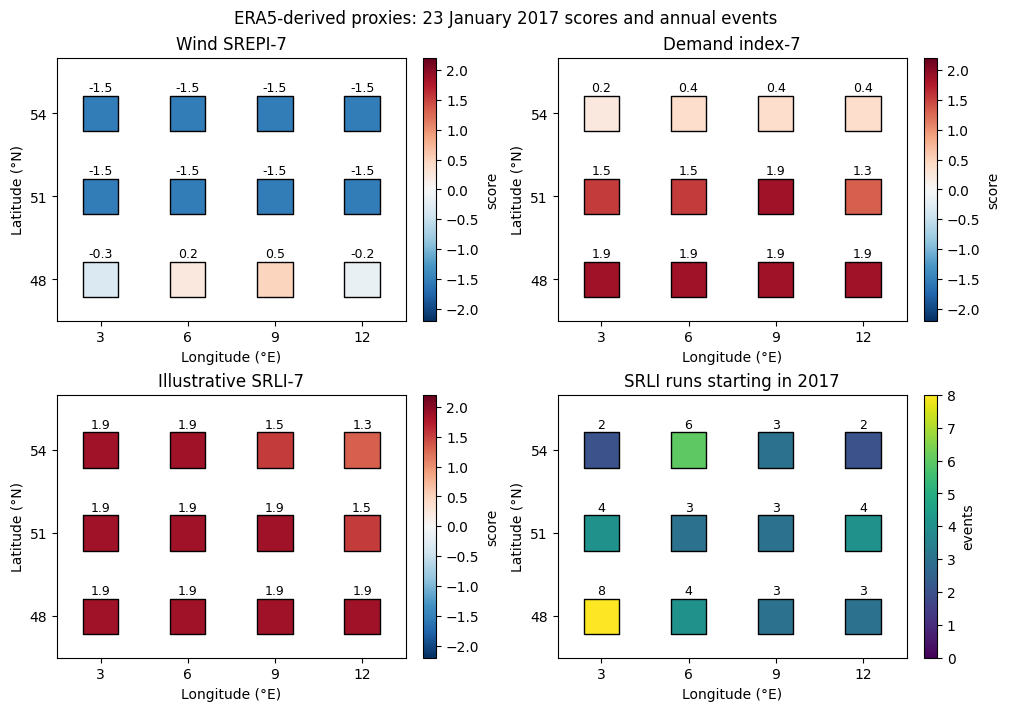

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
map_fields = [
    (scores.srepi.sel(time="2017-01-23"), "Wind SREPI-7", "score", "RdBu_r", -2.2, 2.2),
    (scores.demand.sel(time="2017-01-23"), "Demand index-7", "score", "RdBu_r", -2.2, 2.2),
    (scores.srli.sel(time="2017-01-23"), "Illustrative SRLI-7", "score", "RdBu_r", -2.2, 2.2),
    (stress_events["count"].sel(period=2017), "SRLI runs starting in 2017", "events", "viridis", 0, None),
]
for ax, (field, title, unit, palette, lower, upper) in zip(axes.flat, map_fields):
    field = field.transpose("latitude", "longitude")
    xx, yy = np.meshgrid(field.longitude, field.latitude)
    image = ax.scatter(
        xx, yy, c=field.values, s=650, marker="s", edgecolors="black",
        cmap=plt.get_cmap(palette).with_extremes(bad="0.6"), vmin=lower, vmax=upper,
    )
    for x, y, value in zip(xx.flat, yy.flat, field.values.flat):
        label = f"{value:.1f}" if unit == "score" else f"{value:.0f}"
        ax.text(x, y + 0.8, label, ha="center", fontsize=9)
    ax.set(title=title, xlabel="Longitude (°E)", ylabel="Latitude (°N)",
           xlim=(1.5, 13.5), ylim=(46.5, 56), xticks=[3, 6, 9, 12], yticks=[48, 51, 54])
    fig.colorbar(image, ax=ax, label=unit)
fig.suptitle("ERA5-derived proxies: 23 January 2017 scores and annual events")
plt.show()

## Inspect one cell with surrounding dates

The upper panel compares dimensionless proxies at 51°N, 9°E. The lower panel shows their standardized indices.
The shaded interval is the independently documented 16–27 January case.
Line styles and labels distinguish the series without reliance on color. Dashed horizontal lines mark the strict event thresholds.
The table below exposes the daily scores for the case. A plot or a historical coincidence does not validate the proxy assumptions.

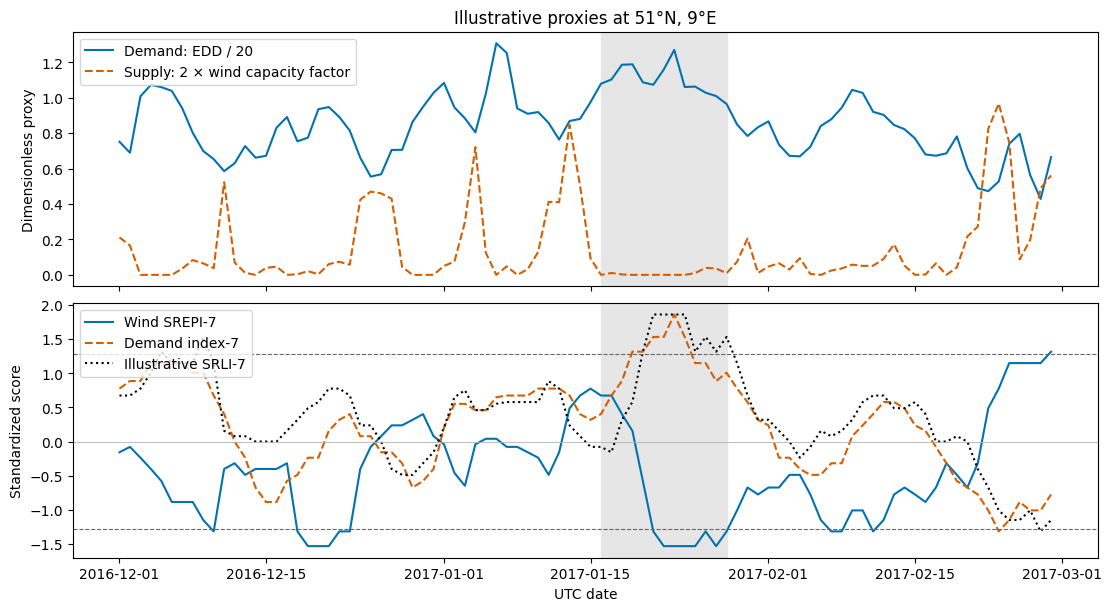

,srepi,demand,srli
time,,,
2017-01-16,0.674,0.402,-0.078
2017-01-17,0.674,0.674,-0.157
2017-01-18,0.402,0.887,0.319
2017-01-19,0.157,1.318,0.579
2017-01-20,-0.579,1.318,1.318
2017-01-21,-1.318,1.534,1.863
2017-01-22,-1.534,1.534,1.863
2017-01-23,-1.534,1.863,1.863
2017-01-24,-1.534,1.534,1.863


In [7]:
window = slice("2016-12-01", "2017-02-28")
point_scores = scores.sel(**cell, time=window)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout="constrained")
axes[0].plot(demand_proxy.time.sel(time=window), demand_proxy.sel(**cell, time=window),
             label="Demand: EDD / 20", color="#0072B2", linestyle="-")
axes[0].plot(wind_cf.time.sel(time=window), 2 * wind_cf.sel(**cell, time=window),
             label="Supply: 2 × wind capacity factor", color="#D55E00", linestyle="--")
axes[0].set(ylabel="Dimensionless proxy", title="Illustrative proxies at 51°N, 9°E")
for name, label, style, color in [
    ("srepi", "Wind SREPI-7", "-", "#0072B2"),
    ("demand", "Demand index-7", "--", "#D55E00"),
    ("srli", "Illustrative SRLI-7", ":", "black"),
]:
    axes[1].plot(point_scores.time, point_scores[name], label=label, linestyle=style, color=color)
for level in [-threshold, threshold]:
    axes[1].axhline(level, color="0.4", linestyle="--", linewidth=0.8)
axes[1].axhline(0, color="0.7", linewidth=0.6)
axes[1].set(ylabel="Standardized score", xlabel="UTC date")
for ax in axes:
    ax.axvspan(pd.Timestamp(case_start), pd.Timestamp(case_end) + pd.Timedelta(days=1), color="0.9", zorder=0)
    ax.legend(loc="upper left")
plt.show()
display(scores.sel(**cell, time=slice(case_start, case_end)).to_dataframe()[["srepi", "demand", "srli"]].round(3))

## Obtain a larger record through the CDS API

The cached subset comes from the anonymously readable ARCO redistribution. A CDS account is **not** required to run this notebook.
For a new hourly ERA5 study, follow the [official CDS API setup](https://cds.climate.copernicus.eu/how-to-api):

1. Register a CDS account. Accept the dataset terms on the [ERA5 single-level download page](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=download).
2. Keep the personal access token in `$HOME/.cdsapirc`, outside the repository. Never paste it into a notebook or commit it.
3. Install the optional client in your own environment with `uv pip install 'cdsapi>=0.7.7'`.
4. Select the variables, area, dates, and hours on the dataset page. Use **Show API request code** to confirm the current schema.

This example request is documentation, not an executed cell. Repeat it by month across a complete Calibration Period.
Do not replace the cache with this one-month request: it has a different grid and does not provide enough calibration years.

```python
import cdsapi

cdsapi.Client().retrieve(
    "reanalysis-era5-single-levels",
    {
        "product_type": ["reanalysis"],
        "variable": ["2m_temperature", "10m_u_component_of_wind", "10m_v_component_of_wind"],
        "year": ["2017"], "month": ["01"],
        "day": [f"{day:02d}" for day in range(1, 32)],
        "time": [f"{hour:02d}:00" for hour in range(24)],
        "area": [54, 3, 48, 12],  # north, west, south, east
        "data_format": "netcdf", "download_format": "unarchived",
    },
    "era5_energy_2017_01.nc",
)
```

Align the downloaded fields exactly. Compute wind speed with `np.hypot(u10, v10)` at each timestamp.
Apply the hub-height profile and capacity-factor curve **before** daily averaging.
Use daily mean temperature for this library's mean-based degree days.
For exact regeneration of the committed six-hourly cache, run `uv run --group dev scripts/prepare_energy_demo_inputs.py` instead.
That command reads roughly 2 GB of remote global chunks; the small output size does not describe transfer cost.
The [C3S energy-indicator product](https://doi.org/10.24381/3bb607bd) is an alternative input, not the source of this cache.

## Attribution and evidence limits

Modified ECMWF ERA5 reanalysis data, © European Centre for Medium-Range Weather Forecasts (ECMWF), accessed through Google Research's ARCO-ERA5 redistribution.
The ERA5 catalogue lists [CC-BY-4.0](https://creativecommons.org/licenses/by/4.0/).
Contains modified Copernicus Climate Change Service information 2022.
Neither the European Commission nor ECMWF is responsible for any use that may be made of the Copernicus information or data it contains.
The [cache record](fixtures/energy_era5_README.md) documents the modifications and data terms separately from this repository's software licence.

- Hersbach et al. (2020), [The ERA5 global reanalysis](https://doi.org/10.1002/qj.3803); [single-level dataset DOI](https://doi.org/10.24381/cds.adbb2d47).
- [ARCO-ERA5](https://github.com/google-research/arco-era5), source redistribution and regridding.
- Allen & Otero (2023), [Standardised indices to monitor energy droughts](https://doi.org/10.1016/j.renene.2023.119206).
- ENTSO-E (2017), [January cold-spell report](https://eepublicdownloads.entsoe.eu/clean-documents/news/170530_Managing_Critical_Grid_Situations-Success_and_Challenges.pdf), Belgium section and Figure 4.36.

The notebook supplies execution and consistency checks, not an external oracle for generation, demand, or event dates.
The [energy guide](https://climate-indices.readthedocs.io/en/latest/energy_applications.html) and
[validation inventory](https://github.com/monocongo/climate_indices/blob/main/VALIDATION.md) describe the library's evidence and limits.